# Projeto de Fusão de Informação em Análises de Dados

<div style="width: 100%; overflow: hidden;">

    <a href="http://www.uc.pt/fctuc/dei/">

    <div style="display: block;margin-left: auto;margin-right: auto; width: 100%;"><img src="https://eden.dei.uc.pt/~naml/images_ecos/dei25.png"  /></div>

    </a>

</div>

---

#### Afonso Rodrigues -- 2020242400 <p>Emanuel Pacheco -- 20_


### Criação dos dados artificiais para serem utilizados no projeto
#### Professora aconselhou aos dados terem de ser criados por nós, uma vez que não são entregues no enunciado

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
# Parâmetros da trajetória
theta = np.linspace(np.pi+0.25, -np.pi/2, 100)  # Ângulo de 90° a 360°
radius = 10  # Raio do quase-círculo
center = (0,10)  # Centro do círculo

# Gerar a trajetória quase-circular
x = radius * np.cos(theta) + center[0]
y = radius * np.sin(theta) + center[1]
# Time vector (assuming constant speed)
time = np.linspace(0, 10, len(theta))  # Assuming a time vector from 0 to 10 seconds
speed = np.sin(np.linspace(0, np.pi, len(time))) * 1500


array([0.00000000e+00, 4.75919002e+01, 9.51358795e+01, 1.42584065e+02,
       1.89888680e+02, 2.37002094e+02, 2.83876867e+02, 3.30465799e+02,
       3.76721981e+02, 4.22598835e+02, 4.68050169e+02, 5.13030215e+02,
       5.57493683e+02, 6.01395803e+02, 6.44692368e+02, 6.87339783e+02,
       7.29295104e+02, 7.70516087e+02, 8.10961226e+02, 8.50589796e+02,
       8.89361894e+02, 9.27238479e+02, 9.64181415e+02, 1.00015350e+03,
       1.03511852e+03, 1.06904126e+03, 1.10188756e+03, 1.13362436e+03,
       1.16421970e+03, 1.19364276e+03, 1.22186393e+03, 1.24885478e+03,
       1.27458814e+03, 1.29903811e+03, 1.32218005e+03, 1.34399066e+03,
       1.36444799e+03, 1.38353144e+03, 1.40122179e+03, 1.41750123e+03,
       1.43235336e+03, 1.44576324e+03, 1.45771735e+03, 1.46820367e+03,
       1.47721163e+03, 1.48473216e+03, 1.49075770e+03, 1.49528216e+03,
       1.49830101e+03, 1.49981119e+03, 1.49981119e+03, 1.49830101e+03,
       1.49528216e+03, 1.49075770e+03, 1.48473216e+03, 1.47721163e+03,
      

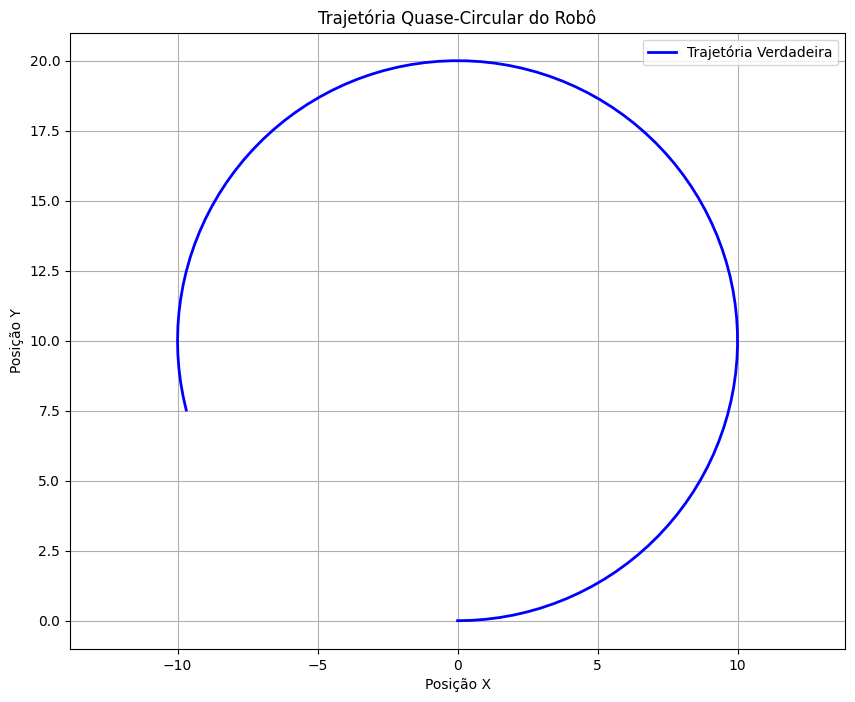

In [3]:
# Função para plotar a trajetória e as elipses de covariância
def plot_trajectory(x, y):
    plt.figure(figsize=(10, 8))
    
    # Trajetória verdadeira
    plt.plot(x, y, 'b-', label='Trajetória Verdadeira', linewidth=2)
    
    plt.xlabel('Posição X')
    plt.ylabel('Posição Y')
    plt.title('Trajetória Quase-Circular do Robô')
    plt.legend()
    plt.grid(True)
    plt.axis('equal')
    plt.show()
    
plot_trajectory(x, y)

#### CSV files creation

In [ ]:
import os
if not os.path.exists('robot_trajectory.csv'):
   # Combine time, x, y, and theta into a single 2D array
   data = np.column_stack((time, x, y, theta))

   # Save the data to a CSV file
   np.savetxt('robot_trajectory.csv', 
              np.array([x, y, theta, speed]).T, 
              delimiter=',', header='x,y,orientation,speed', comments='')

   print("CSV file 'robot_trajectory.csv' has been generated.")

print ("robot_trajectory.csv already exists. Skipping the generation of the file.")
   
if not os.path.exists('sensor_data.csv'):
   
   # Save the sensor data to a CSV file
   data = np.column_stack((time, speed, theta))
   np.savetxt('sensor_data.csv', 
              np.array([speed, theta]).T, 
              delimiter=',', header='speed,orientation', comments='')
   
   print("CSV file 'sensor_data.csv' has been generated.")
print ("sensor_data.csv already exists. Skipping the generation of the file.")   


robot_trajectory.csv already exists. Skipping the generation of the file.
sensor_data.csv already exists. Skipping the generation of the file.


In [41]:
# In case of needing to override previous defined files

np.savetxt('robot_trajectory.csv', np.array([x, y, np.deg2rad(theta), speed]).T,  delimiter=',', header='x,y,orientation,speed', comments='')
np.savetxt('sensor_data.csv', np.array([speed, np.deg2rad(theta)]).T, delimiter=',', header='speed,orientation', comments='')

In [42]:
gnss_data = np.loadtxt("gnss_data.csv", delimiter=",",skiprows=1)
x_gnss = gnss_data[:,0]
y_gnss = gnss_data[:,1]

robot_trajectory = np.loadtxt("robot_trajectory.csv", delimiter=",",skiprows=1)
x_true = robot_trajectory[:,0]
y_true = robot_trajectory[:,1]
orientation = robot_trajectory[:,2]
velocity = robot_trajectory[:,3]

sensor_data = np.loadtxt("sensor_data.csv", delimiter=",",skiprows=1)
speed = sensor_data[:,0]
orientation = sensor_data[:,1]
time_step = time[2] - time[1]
# xk = np.a

In [ ]:
def delta_t(t1,t2):
   return t2-t1

A = np.array(([1, 0, 0, 0],
             [0, 1, 0, 0],
             [0, 0, 1, 0],
             [0, 0, 0, 0]))

def get_B(time_step, degree):
   rad = np.deg2rad(degree)
   return np.array(([time_step*np.cos(rad), 0],
                    [time_step*np.sin(rad), 0],
                    [0, time_step],
                    [1, 0]))

x_k = robot_trajectory[0]
u_k = sensor_data[0]

B = get_B(time_step, x_k[2])
x_k1 = A @ x_k + B @ u_k

print(x_k1)

[-9.68912422  7.52596041  0.0651737   0.        ]


In [ ]:
a = np.ones(100)

def recursive_prediction(x_k, u_k, limit=100, current_depth=0):
   if current_depth == limit:
      print("Limit reached")
      return
   
   u_k = sensor_data[current_depth]
   
   B = get_B(time_step, x_k[2])
   x_k1 = A @ x_k + B @ u_k
   return recursive_prediction(x_k1, u_k, limit, current_depth+1,)